# ESAA YB 미니프로젝트 2 — 와인 품질 분류 (통합본)

DACON 와인 품질 분류 데이터(학습 5,497병, 테스트 1,000병)로 와인의 품질 등급(3~9)을 분류한다. 평가 지표는 정확도(Accuracy)이며, 최종 리더보드 점수는 **0.713**이다.

## 공통 구조

모든 단계는 같은 순서를 따른다.

> **질문** → **단계별 검증** → **시각화** → **해석**(결과 + 결정)

데이터에서 확인한 사실이 다음 단계의 결정으로 이어지도록 썼다. 효과가 없었던 실험도 결정의 근거이므로 함께 남긴다.

## 목차

| 번호 | 주제 | 결론 요약 |
|---|---|---|
| 1 | 데이터 구조 | 결측치 없음, `index` 제거, 종류만 문자형 |
| 2 | 중복 데이터 | 학습 중복 858행, 테스트 303행이 학습과 동일, 라벨 충돌 0건 |
| 3 | 품질 등급 분포 | 5~7등급이 93.3%, 기준선 0.4395 |
| 4 | 학습·테스트 분포 비교 | 두 데이터의 분포가 거의 같음 |
| 5 | 변수별 분포와 극단값 | 극단값의 대부분이 레드 와인 → 제거하지 않음 |
| 6 | 변수 간 상관 | 상관이 약한 변수도 필요, 종류가 상관 구조를 바꿈 |
| 7 | 레드·화이트 비교 | 종류를 변수로 넣고 모델은 통합 |
| 8 | 등급별 차이 | 고등급과 저등급을 가르는 변수가 다름, 인접 등급이 크게 겹침 |
| 9 | 전처리 결정 | 중복 유지, 불균형 처리 안 함, 결합 이산화황 추가 |
| 10 | 검증 설계 | 중복을 고려하면 정확도가 약 0.10 내려감 |
| 11 | 분류 모델 3종 | Extra Trees ≥ 랜덤 포레스트 > XGBoost |
| 12 | 앙상블 | 랜덤 포레스트 + Extra Trees + 스태킹 → 리더보드 0.709 |
| 13 | 0.709 이후의 정체와 원인 | 변형 15개가 모두 0.709 미만, 원인은 라벨 변동과 트리 모델의 같은 오답 |
| 14 | 최종 모델 | 0.709 + TabICL → 리더보드 0.713 |
| 15 | 종합 | 관찰에서 결정까지의 흐름, 효과가 없던 실험, 한계 |

---

## 0. 준비

- 그래프의 한글 표시를 위해 맥북 기본 글꼴인 AppleGothic을 쓴다.
- 데이터가 없으면 처음 실행할 때 내려받는다.

In [1]:
import os
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline
from tabicl import TabICLClassifier

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
DATA_URL = 'https://bit.ly/3i4n1QB'

if not os.path.exists('data/train.csv'):
    urllib.request.urlretrieve(DATA_URL, 'wine.zip')
    with zipfile.ZipFile('wine.zip') as z:
        z.extractall('data')

train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')
sub = pd.read_csv('data/sample_submission.csv')

features = [c for c in test.columns if c not in ('index', 'type')]
korean_name = {
    'fixed acidity': '산도', 'volatile acidity': '휘발성산', 'citric acid': '시트르산',
    'residual sugar': '발효 후 와인 속에 남아있는 당분', 'chlorides': '염화물',
    'free sulfur dioxide': '독립 이산화황', 'total sulfur dioxide': '총 이산화황',
    'density': '밀도', 'pH': '수소이온농도', 'sulphates': '황산염', 'alcohol': '도수',
}

---

# 1. 데이터 구조

**질문**: 데이터는 어떤 모양이고, 분석 전에 손봐야 할 것이 있는가.

In [3]:
print(train.shape, test.shape)
pd.DataFrame({'자료형': train.dtypes.astype(str), '결측치': train.isnull().sum(),
              '이름': pd.Series(korean_name)}).reindex(train.columns).fillna('')

(5497, 14) (1000, 13)


,자료형,결측치,이름
index,int64,0,
quality,int64,0,
fixed acidity,float64,0,산도
volatile acidity,float64,0,휘발성산
citric acid,float64,0,시트르산
residual sugar,float64,0,발효 후 와인 속에 남아있는 당분
chlorides,float64,0,염화물
free sulfur dioxide,float64,0,독립 이산화황
total sulfur dioxide,float64,0,총 이산화황
density,float64,0,밀도


**해석**

- 학습 데이터는 5,497행 14열, 테스트 데이터는 1,000행 13열이다. 테스트에는 맞혀야 할 `quality`가 없다.
- 모든 변수에 결측치가 없다.
- `index`는 식별용 번호이므로 학습에서 제외하고, 문자형인 종류(`type`)는 숫자로 바꾼다.

---

# 2. 중복 데이터

**질문**: 성분이 완전히 같은 와인이 반복되는가. 반복된다면 품질도 같은가.

같은 와인이 교차검증의 학습 폴드와 검증 폴드에 동시에 들어가면, 모델은 정답을 외워서 맞히게 되어 검증 점수가 실제보다 높아진다. 그래서 분석 전에 먼저 확인한다.

In [4]:
key_cols = features + ['type']
duplicate_count = train.duplicated(subset=key_cols).sum()
overlap_count = test[key_cols].merge(train[key_cols].drop_duplicates(), how='inner').shape[0]
conflict_count = (train.groupby(key_cols)['quality'].nunique() > 1).sum()

print(f'학습 데이터 중복 행: {duplicate_count}개 ({duplicate_count / len(train):.1%})')
print(f'테스트 중 학습 데이터와 성분이 같은 행: {overlap_count}개')
print(f'성분은 같고 품질이 다른 경우: {conflict_count}건')

학습 데이터 중복 행: 858개 (15.6%)
테스트 중 학습 데이터와 성분이 같은 행: 303개
성분은 같고 품질이 다른 경우: 0건


**해석**

- 학습 데이터의 15.6%(858행)가 다른 행과 성분이 완전히 같고, 테스트 1,000행 중 303행(30.3%)도 학습 데이터에 그대로 있다.
- 성분이 같으면 품질도 항상 같다(충돌 0건). 따라서 중복 행은 학습을 방해하지 않는다.
- **결정**: 중복 행은 지우지 않는다(9장에서 확인). 테스트 중 학습 데이터와 같은 303행은 학습 데이터의 품질을 그대로 쓴다. 교차검증에서는 같은 와인이 학습·검증에 나뉘지 않도록 따로 확인한다(10장).

---

# 3. 품질 등급 분포

**질문**: 맞혀야 할 품질 등급은 고르게 분포하는가.

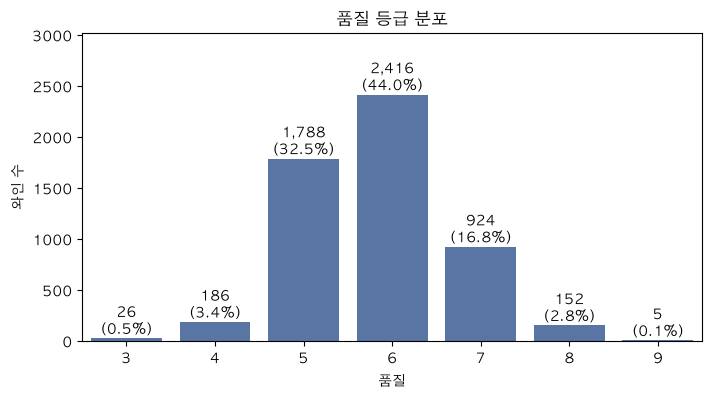

5~7등급 비율: 93.3%
기준선(전부 6등급으로 예측): 0.4395


In [5]:
quality_counts = train['quality'].value_counts().sort_index()

plt.figure(figsize=(8, 4))
ax = sns.countplot(data=train, x='quality', color='#4C72B0')
ax.bar_label(ax.containers[0], labels=[f'{c:,}\n({c / len(train):.1%})' for c in quality_counts])
ax.set_ylim(0, quality_counts.max() * 1.25)
ax.set_title('품질 등급 분포')
ax.set_xlabel('품질')
ax.set_ylabel('와인 수')
plt.show()

print(f'5~7등급 비율: {quality_counts.loc[5:7].sum() / len(train):.1%}')
print(f'기준선(전부 6등급으로 예측): {(train["quality"] == 6).mean():.4f}')

**해석**

- 품질은 3~9등급이지만 5~7등급이 93.3%이고, 6등급만 44.0%다. 3등급은 26병, 9등급은 5병뿐이다.
- 모든 와인을 6등급으로 예측해도 정확도가 0.4395다. 이 값을 **기준선**으로 삼아 모델 성능을 비교한다.
- 정확도는 와인 한 병 한 병을 똑같이 세므로, 점수는 사실상 5·6·7등급을 얼마나 잘 가르느냐로 결정된다.

---

# 4. 학습·테스트 분포 비교

**질문**: 학습 데이터로 만든 모델을 테스트 데이터에 그대로 써도 되는가.

In [6]:
compare = pd.DataFrame({'학습 평균': train[features].mean(), '테스트 평균': test[features].mean()})
compare['차이(%)'] = (compare['테스트 평균'] / compare['학습 평균'] - 1) * 100
display(compare.round(3))
pd.DataFrame({'학습': train['type'].value_counts(normalize=True),
              '테스트': test['type'].value_counts(normalize=True)}).round(3)

,학습 평균,테스트 평균,차이(%)
fixed acidity,7.210,7.244,0.468
volatile acidity,0.338,0.348,2.888
citric acid,0.319,0.319,0.184
residual sugar,5.438,5.472,0.616
chlorides,0.056,0.057,2.629
free sulfur dioxide,30.418,31.117,2.299
total sulfur dioxide,115.566,116.724,1.001
density,0.995,0.995,0.015
pH,3.220,3.213,-0.202
sulphates,0.531,0.535,0.912


,학습,테스트
type,,
white,0.757,0.739
red,0.243,0.261


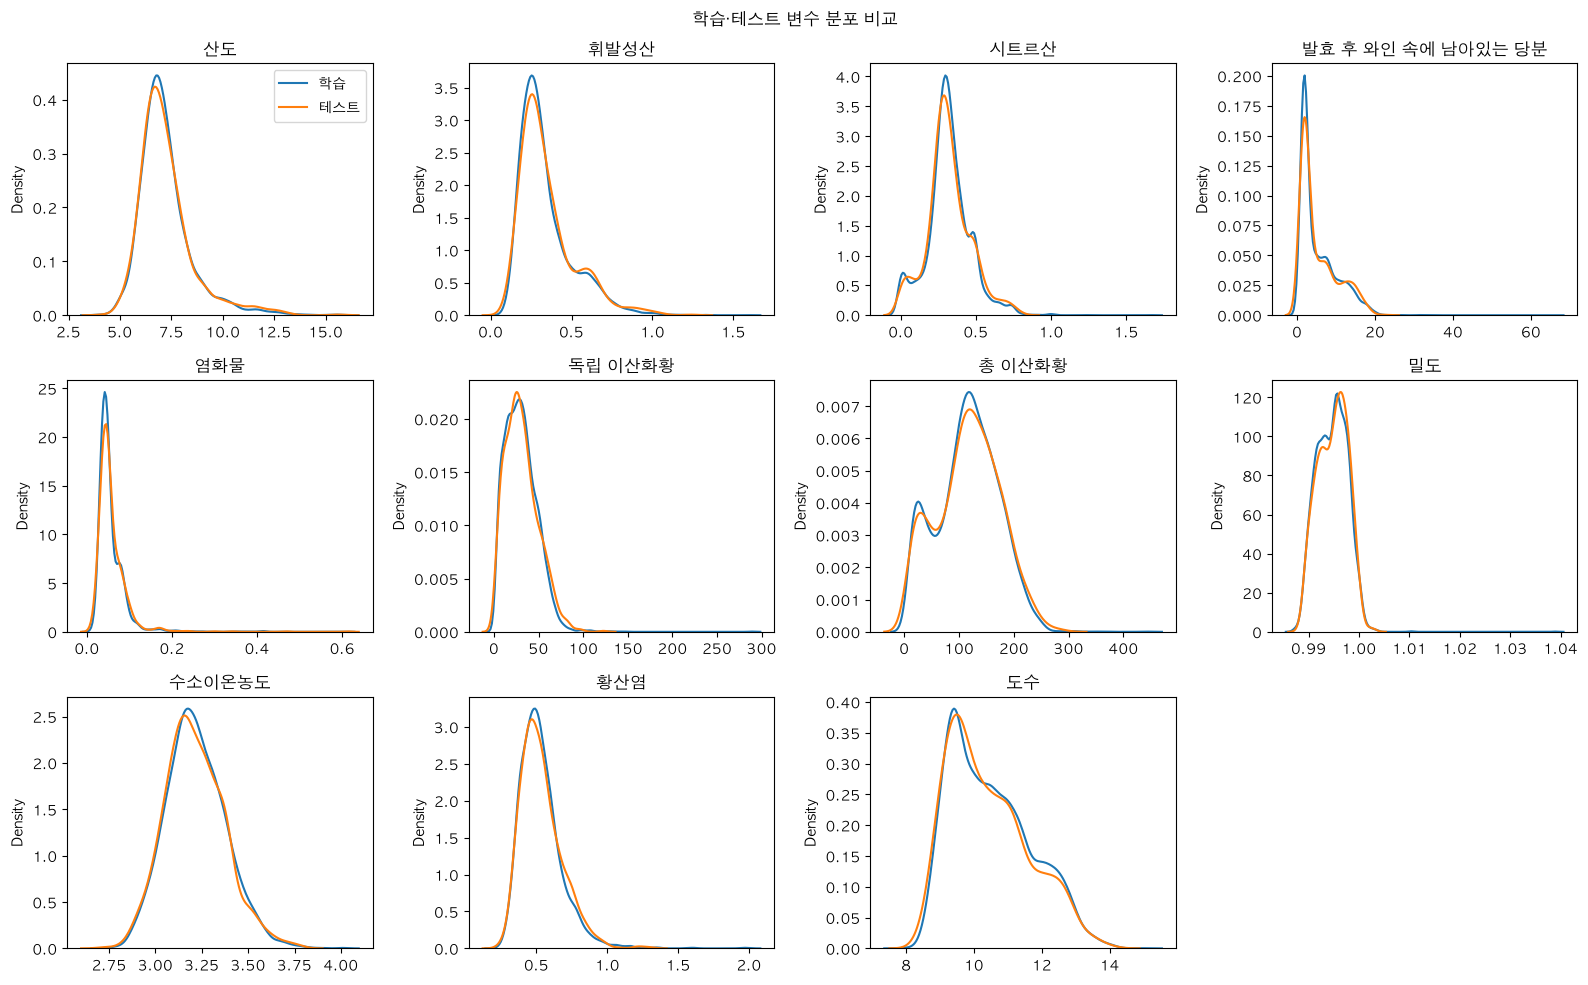

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), features):
    sns.kdeplot(train[col], ax=ax, label='학습')
    sns.kdeplot(test[col], ax=ax, label='테스트')
    ax.set_title(korean_name[col])
    ax.set_xlabel('')
axes.flatten()[0].legend()
axes.flatten()[-1].axis('off')
plt.suptitle('학습·테스트 변수 분포 비교')
plt.tight_layout()
plt.show()

**해석**

- 모든 변수의 평균 차이가 ±3% 이내이고, 분포 곡선도 거의 겹친다. 화이트 와인 비율도 75.7%와 73.9%로 비슷하다.
- **결정**: 학습 데이터에서 검증한 결과가 테스트에도 그대로 적용된다고 보고, 별도의 분포 보정은 하지 않는다.

---

# 5. 변수별 분포와 극단값

**질문**: 변수가 한쪽으로 치우쳐 있거나 극단값이 많은가. 극단값은 지워야 하는가.

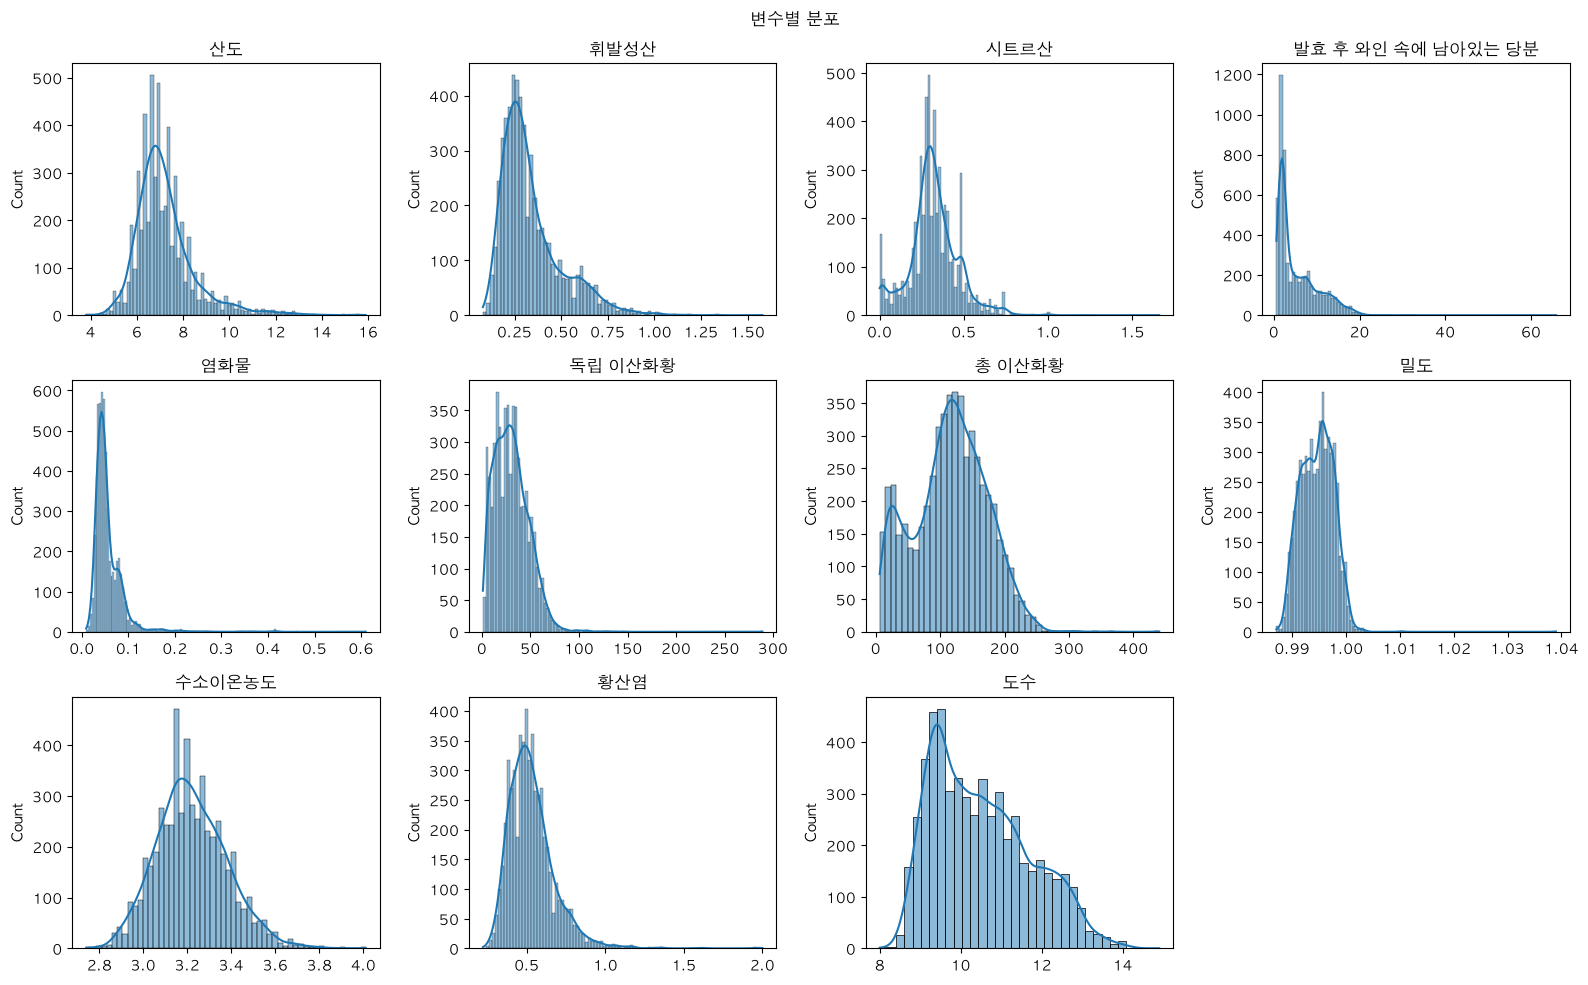

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), features):
    sns.histplot(train[col], kde=True, ax=ax)
    ax.set_title(korean_name[col])
    ax.set_xlabel('')
axes.flatten()[-1].axis('off')
plt.suptitle('변수별 분포')
plt.tight_layout()
plt.show()

In [9]:
skewness = train[features].apply(skew).sort_values(ascending=False)
skewed_cols = skewness[skewness > 1].index

q1, q3 = train[skewed_cols].quantile(0.25), train[skewed_cols].quantile(0.75)
iqr = q3 - q1
is_outlier = (train[skewed_cols] < q1 - 1.5 * iqr) | (train[skewed_cols] > q3 + 1.5 * iqr)
outlier_table = pd.DataFrame({
    '왜도': skewness[skewed_cols],
    '극단값 수': is_outlier.sum(),
    '극단값 비율(%)': is_outlier.mean() * 100,
    '극단값 중 레드 비율(%)': [(train.loc[is_outlier[c], 'type'] == 'red').mean() * 100 for c in skewed_cols],
})
print(f'전체 레드 와인 비율: {(train["type"] == "red").mean():.1%}')
outlier_table.round(2)

전체 레드 와인 비율: 24.3%


,왜도,극단값 수,극단값 비율(%),극단값 중 레드 비율(%)
chlorides,5.19,259,4.71,65.25
sulphates,1.91,161,2.93,80.75
fixed acidity,1.71,294,5.35,91.16
residual sugar,1.50,106,1.93,0.00
volatile acidity,1.50,314,5.71,90.45
free sulfur dioxide,1.31,47,0.86,0.00


**해석**

- 염화물(왜도 5.19), 황산염, 산도, 당분, 휘발성산, 독립 이산화황의 6개 변수가 오른쪽으로 크게 치우쳐 있다.
- 극단값이 측정 오류라면 레드와 화이트에서 고르게 나와야 한다. 그런데 산도·휘발성산 극단값의 90% 이상이 레드 와인으로, 전체 레드 비율(24.3%)보다 훨씬 높다. 즉 극단값의 상당수는 오류가 아니라 **레드 와인의 정상적인 값**이다.
- 총 이산화황의 봉우리 두 개도 총 이산화황이 낮은 레드와 높은 화이트가 섞여 생긴 모양이다.
- **결정**: 극단값을 지우면 레드 와인이 집중적으로 삭제되므로 지우지 않는다. 트리 모델은 값의 크기 순서만 쓰므로 치우친 분포의 영향을 거의 받지 않아 로그 변환도 하지 않는다. 등급별 비교에서는 평균 대신 중앙값을 쓴다.

---

# 6. 변수 간 상관

**질문**: 품질과 관련 있는 변수는 무엇이고, 상관이 약한 변수는 버려도 되는가. 변수끼리 겹치는 구조가 있는가.

이 장의 성능 비교는 랜덤 포레스트(트리 300개)와 5-Fold 층화 교차검증으로 고정한다.

In [10]:
X_raw = train[features].assign(is_white=(train['type'] == 'white').astype(int))
y = train['quality']
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rf300 = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)

def cv_accuracy(model, X, target=y, splitter=cv, groups=None):
    scores = cross_val_score(model, X, target, cv=splitter, groups=groups)
    return round(scores.mean(), 4), round(scores.std(), 4)

quality_corr = pd.DataFrame({
    'pearson': train[features].corrwith(train['quality']),
    'spearman': train[features].corrwith(train['quality'], method='spearman'),
}).sort_values('pearson', key=abs, ascending=False)
quality_corr.index = [korean_name[c] for c in quality_corr.index]
quality_corr.round(3)

,pearson,spearman
도수,0.440,0.444
밀도,-0.300,-0.321
휘발성산,-0.262,-0.252
염화물,-0.198,-0.292
시트르산,0.079,0.099
산도,-0.077,-0.097
독립 이산화황,0.056,0.089
황산염,0.042,0.035
총 이산화황,-0.040,-0.052
발효 후 와인 속에 남아있는 당분,-0.033,-0.014


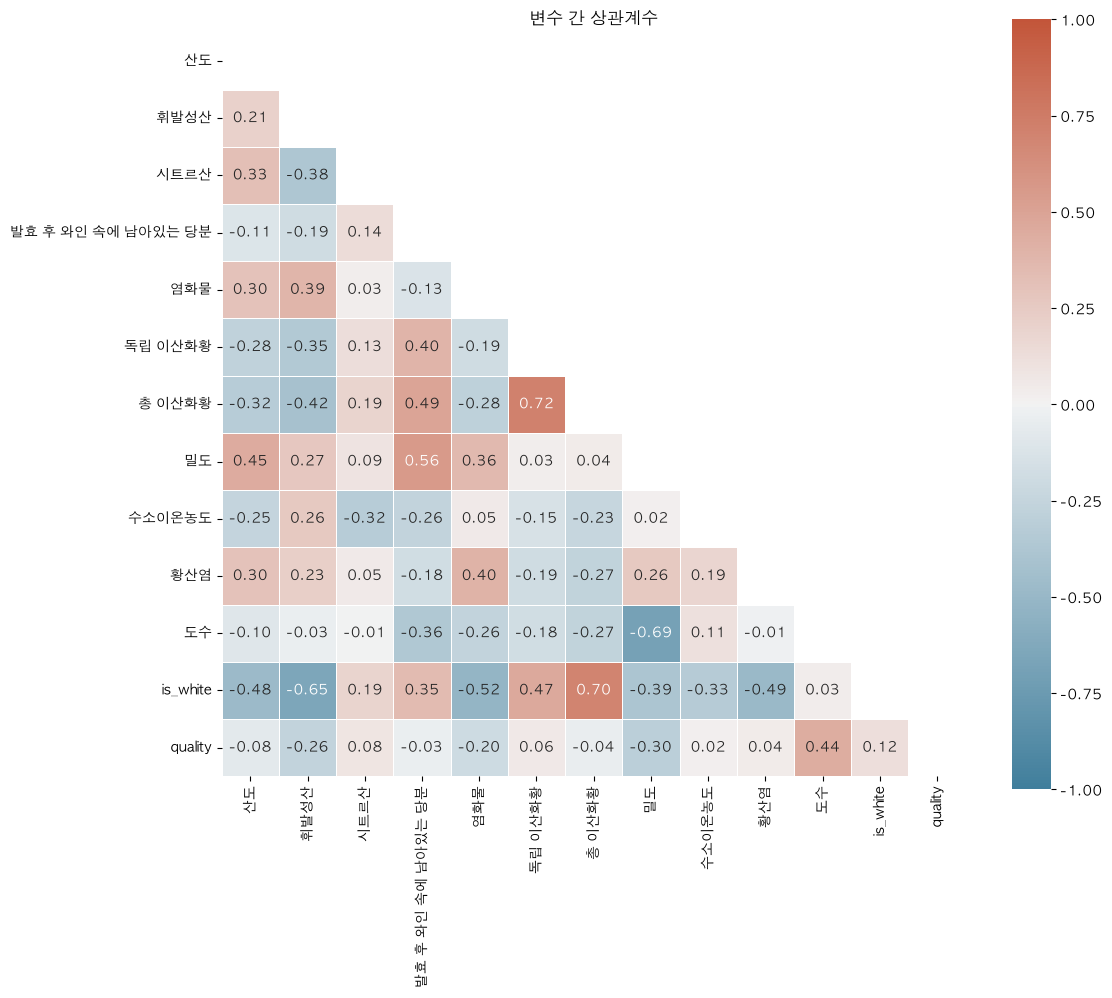

In [11]:
corr = X_raw.assign(quality=y).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(corr, mask=mask, cmap=sns.diverging_palette(230, 20, as_cmap=True), vmin=-1, vmax=1,
            annot=True, fmt='.2f', square=True, linewidths=0.5,
            xticklabels=[korean_name.get(c, c) for c in corr.columns],
            yticklabels=[korean_name.get(c, c) for c in corr.columns])
plt.title('변수 간 상관계수')
plt.show()

### 1단계. 상관이 약한 변수를 빼도 되는가

품질과의 상관계수 절댓값이 0.2 이상인 변수(도수, 밀도, 휘발성산, 염화물)와 종류만 남겨 성능을 비교한다.

In [12]:
strong_cols = ['alcohol', 'density', 'volatile acidity', 'chlorides', 'is_white']
pd.DataFrame({
    '전체 12개 변수': cv_accuracy(rf300, X_raw),
    '상관이 강한 5개 변수': cv_accuracy(rf300, X_raw[strong_cols]),
}, index=['정확도', '표준편차']).T

,정확도,표준편차
전체 12개 변수,0.668,0.0092
상관이 강한 5개 변수,0.642,0.0102


### 2단계. 변수끼리 겹치는 구조 — 다중공선성(VIF)

VIF는 한 변수가 나머지 변수들로 얼마나 설명되는지를 나타내며, 10을 넘으면 중복으로 본다.

In [13]:
def vif(df):
    return pd.Series({c: 1 / (1 - LinearRegression().fit(df.drop(columns=c), df[c]).score(df.drop(columns=c), df[c]))
                      for c in df.columns})

vif_table = vif(train[features]).sort_values(ascending=False).to_frame('VIF')
vif_table.index = [korean_name[c] for c in vif_table.index]
display(vif_table.round(2))
pd.DataFrame({name: cv_accuracy(rf300, X_raw.drop(columns=col))
              for name, col in [('밀도 제외', 'density'), ('총 이산화황 제외', 'total sulfur dioxide'),
                                ('당분 제외', 'residual sugar')]},
             index=['정확도', '표준편차']).T

,VIF
밀도,15.48
발효 후 와인 속에 남아있는 당분,7.08
산도,4.72
도수,4.69
총 이산화황,2.92
수소이온농도,2.47
독립 이산화황,2.11
휘발성산,1.94
염화물,1.65
시트르산,1.59


,정확도,표준편차
밀도 제외,0.6707,0.0053
총 이산화황 제외,0.6676,0.0071
당분 제외,0.6675,0.0105


### 3단계. 선형 상관이 놓치는 관계 — 상호정보량

상관계수는 직선 관계만 잰다. 상호정보량은 곡선 관계까지 잡는다.

In [14]:
mutual_info = pd.Series(mutual_info_classif(train[features], y, random_state=42), index=features)
mi_table = pd.DataFrame({'|pearson|': train[features].corrwith(y).abs(), '상호정보량': mutual_info})
mi_table['순위 변화'] = mi_table['|pearson|'].rank(ascending=False) - mi_table['상호정보량'].rank(ascending=False)
mi_table.index = [korean_name[c] for c in mi_table.index]
mi_table.sort_values('상호정보량', ascending=False).round(3)

,|pearson|,상호정보량,순위 변화
도수,0.440,0.155,0.0
밀도,0.300,0.150,0.0
휘발성산,0.262,0.069,0.0
발효 후 와인 속에 남아있는 당분,0.033,0.056,6.0
총 이산화황,0.040,0.055,4.0
염화물,0.198,0.052,-2.0
시트르산,0.079,0.043,-2.0
독립 이산화황,0.056,0.040,-1.0
황산염,0.042,0.032,-1.0
산도,0.077,0.021,-4.0


**해석**

- 품질과 선형 상관이 뚜렷한 변수는 도수(0.44), 밀도(−0.30), 휘발성산(−0.26), 염화물(−0.20) 네 개뿐이다. 가장 높은 도수도 0.44에 그쳐 변수 하나로 품질을 설명할 수 없다.
- 그러나 상관이 약한 7개를 빼면 정확도가 0.6680에서 0.6420으로 떨어진다. 표준편차(약 0.01)의 두 배가 넘는 차이다. 상관이 0에 가깝다는 것은 "혼자서는 설명하지 못한다"는 뜻이지 "쓸모없다"는 뜻이 아니다. 실제로 당분과 총 이산화황은 상호정보량 순위가 크게 올라, 직선이 아닌 관계를 갖고 있다.
- 독립 이산화황과 총 이산화황(0.72)은 포함 관계이므로, 차이인 **결합 이산화황**(총 − 독립)을 새 변수로 만들 근거가 된다.
- 밀도는 VIF 15.5로 도수·당분의 합성값에 가깝지만, 빼도 정확도가 크게 달라지지 않는다.
- **결정**: 상관이 약한 변수는 모두 유지한다. 결합 이산화황은 후보로 두고 9장에서 검증한다.

---

# 7. 레드·화이트 비교

**질문**: 레드와 화이트는 성분과 품질의 관계가 같은가. 한 모델로 학습해도 되는가.

In [15]:
is_white = train['type'] == 'white'
type_corr = pd.DataFrame({
    '전체': train[features].corrwith(y),
    '레드': train.loc[~is_white, features].corrwith(y[~is_white]),
    '화이트': train.loc[is_white, features].corrwith(y[is_white]),
})
type_corr['부호 역전'] = np.where(np.sign(type_corr['레드']) != np.sign(type_corr['화이트']), '✓', '')
type_corr.index = [korean_name[c] for c in type_corr.index]
type_corr.round(3)

,전체,레드,화이트,부호 역전
산도,-0.077,0.116,-0.107,✓
휘발성산,-0.262,-0.384,-0.192,
시트르산,0.079,0.201,-0.005,✓
발효 후 와인 속에 남아있는 당분,-0.033,-0.004,-0.090,
염화물,-0.198,-0.129,-0.206,
독립 이산화황,0.056,-0.061,0.011,✓
총 이산화황,-0.040,-0.214,-0.164,
밀도,-0.300,-0.179,-0.298,
수소이온농도,0.018,-0.041,0.091,✓
황산염,0.042,0.258,0.056,


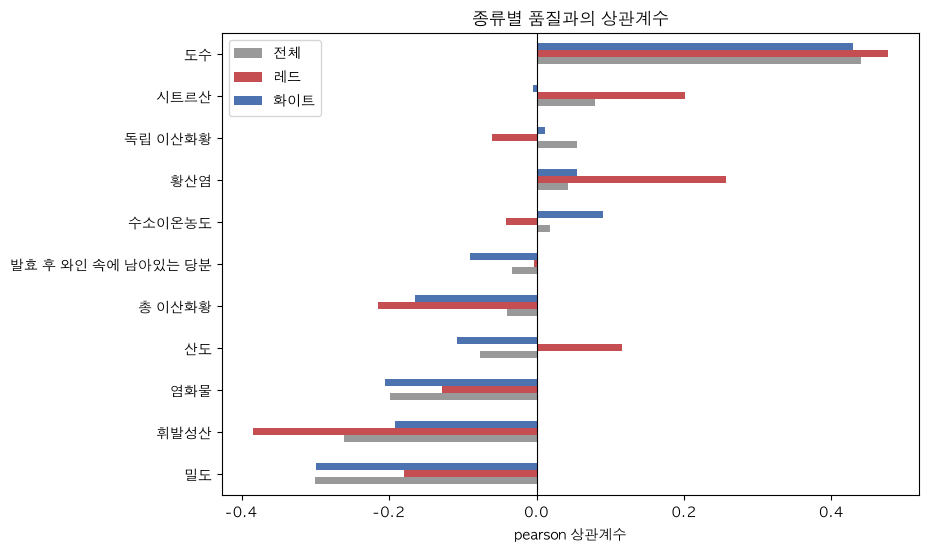

In [16]:
plot_df = type_corr.drop(columns='부호 역전').sort_values('전체')
plot_df.plot.barh(figsize=(9, 6), color=['#999999', '#C44E52', '#4C72B0'])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('종류별 품질과의 상관계수')
plt.xlabel('pearson 상관계수')
plt.show()

### 레드·화이트 모델 분리 vs 통합

In [17]:
red_pred = cross_val_predict(rf300, X_raw[~is_white], y[~is_white], cv=cv)
white_pred = cross_val_predict(rf300, X_raw[is_white], y[is_white], cv=cv)
split_accuracy = (np.sum(red_pred == y[~is_white]) + np.sum(white_pred == y[is_white])) / len(y)
pd.Series({'통합 모델 (종류를 변수로)': cv_accuracy(rf300, X_raw)[0],
           '레드·화이트 분리 모델': round(split_accuracy, 4)}).to_frame('정확도')

,정확도
통합 모델 (종류를 변수로),0.6680
레드·화이트 분리 모델,0.6767


**해석**

- 시트르산, 산도, 독립 이산화황, 수소이온농도 네 변수는 레드와 화이트에서 품질과의 상관 방향이 반대다. 시트르산은 전체로는 거의 무관(0.08)하지만 레드만 보면 0.20이다. 두 종류를 섞으면 한쪽에서만 나타나는 관계가 가려진다.
- 레드와 화이트로 모델을 나누면 정확도가 조금 높지만 차이가 표준편차(약 0.01) 안이다. 레드는 1,338병뿐이라 나누면 학습 데이터가 줄어든다.
- **결정**: 종류를 `is_white`(화이트=1) 변수로 넣고, 모델은 하나로 통합한다.

---

# 8. 등급별 차이

**질문**: 품질 등급에 따라 주요 변수가 어떻게 달라지는가. 등급을 가르는 변수는 등급마다 같은가.

그래프로 전체 보기 → 숫자로 확인 → 종류별로 나누기 → 표본 문제 보완 순서로 본다.

### 1단계. 품질 등급별 박스플롯

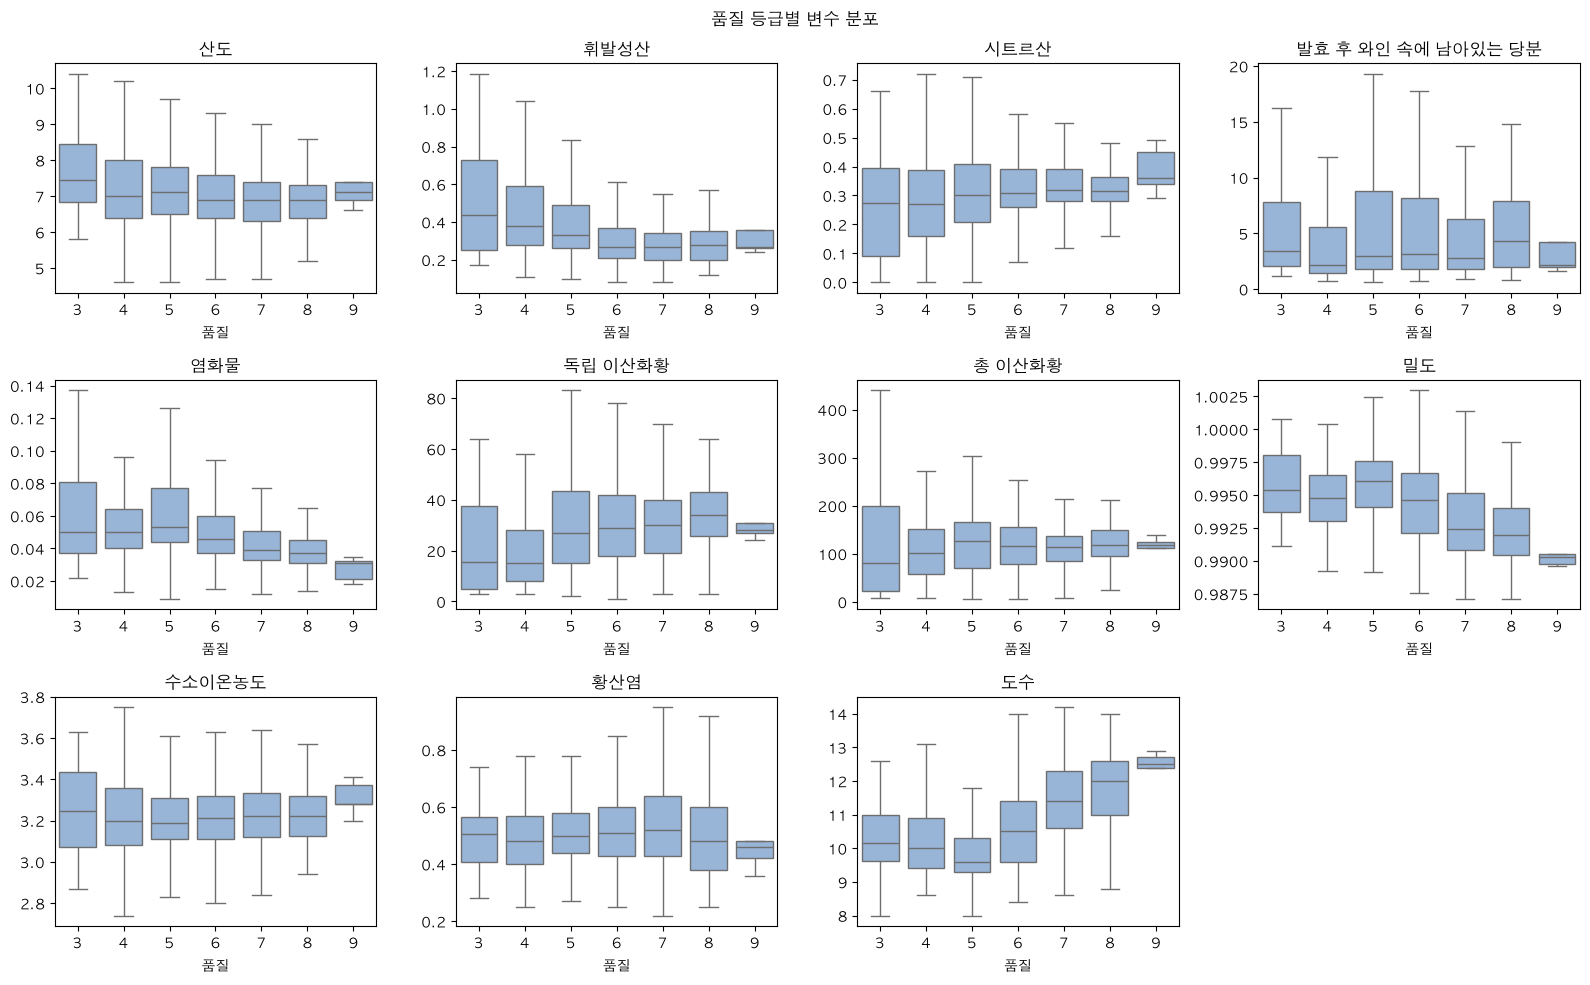

In [18]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(data=train, x='quality', y=col, ax=ax, showfliers=False, color='#8DB3E2')
    ax.set_title(korean_name[col])
    ax.set_xlabel('품질')
    ax.set_ylabel('')
axes.flatten()[-1].axis('off')
plt.suptitle('품질 등급별 변수 분포')
plt.tight_layout()
plt.show()

### 2단계. 등급별 중앙값

In [19]:
key_features = ['alcohol', 'density', 'volatile acidity', 'chlorides']
grade_median = train.groupby('quality')[key_features].median()
grade_median['개수'] = quality_counts
grade_median.rename(columns=korean_name)

,도수,밀도,휘발성산,염화물,개수
quality,,,,,
3,10.15,0.99540,0.435,0.050,26
4,10.00,0.99480,0.380,0.050,186
5,9.60,0.99610,0.330,0.053,1788
6,10.50,0.99460,0.270,0.046,2416
7,11.40,0.99240,0.270,0.039,924
8,12.00,0.99196,0.280,0.037,152
9,12.50,0.99030,0.270,0.031,5


### 3단계. 와인 종류 × 등급별 박스플롯

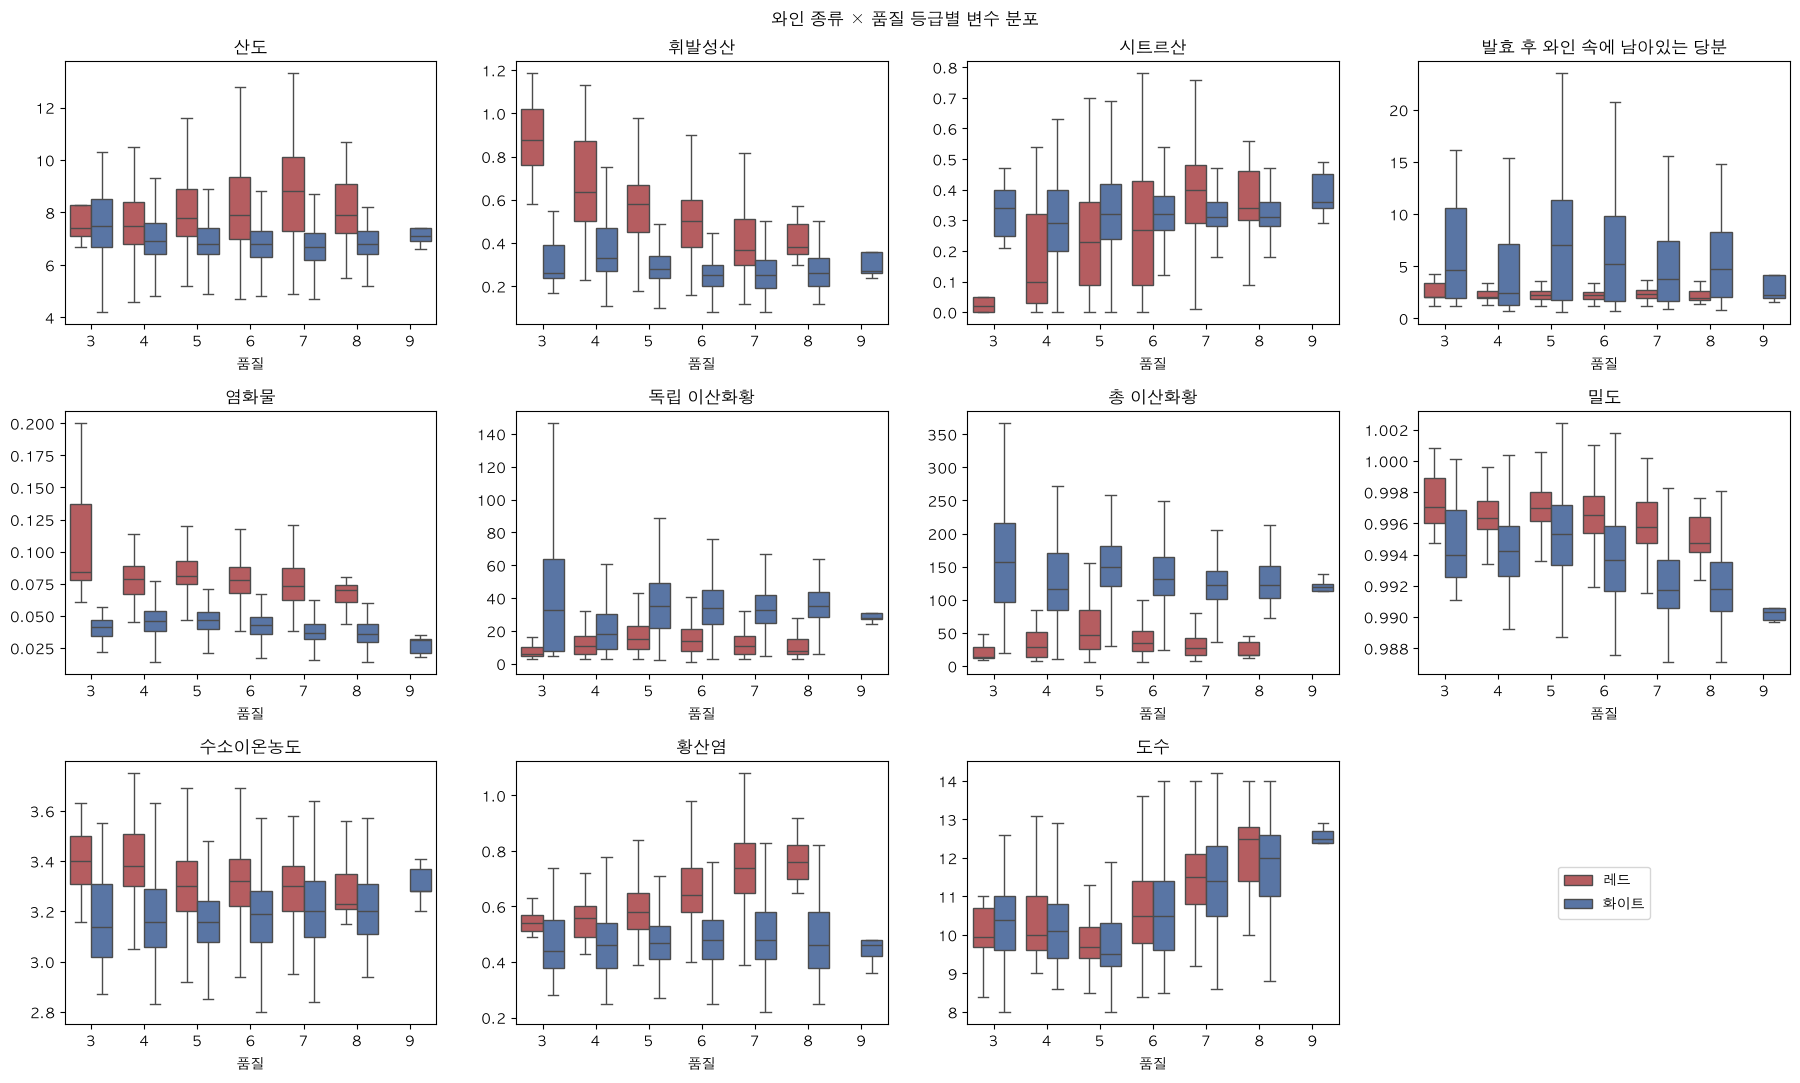

In [20]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(data=train, x='quality', y=col, hue='type', ax=ax, showfliers=False,
                palette={'red': '#C44E52', 'white': '#4C72B0'})
    ax.set_title(korean_name[col])
    ax.set_xlabel('품질')
    ax.set_ylabel('')
    ax.get_legend().remove()
handles, labels = axes.flatten()[0].get_legend_handles_labels()
axes.flatten()[-1].legend(handles, ['레드', '화이트'], loc='center')
axes.flatten()[-1].axis('off')
plt.suptitle('와인 종류 × 품질 등급별 변수 분포')
plt.tight_layout()
plt.show()

### 4단계. 등급 그룹 비교 — 표본이 적은 등급 보완

3등급(26병)과 9등급(5병)은 표본이 너무 적어, 저등급(3~4)·중등급(5~6)·고등급(7~9)으로 묶어 다시 본다.

In [21]:
quality_group = pd.cut(train['quality'], bins=[2, 4, 6, 9], labels=['저등급(3~4)', '중등급(5~6)', '고등급(7~9)'])
group_median = train.groupby(quality_group, observed=True)[key_features].median()
group_median['개수'] = quality_group.value_counts()
group_median.rename(columns=korean_name)

,도수,밀도,휘발성산,염화물,개수
quality,,,,,
저등급(3~4),10.05,0.994940,0.380,0.050,212
중등급(5~6),10.00,0.995385,0.295,0.049,4204
고등급(7~9),11.50,0.992300,0.280,0.039,1081


**해석**

- 등급이 높을수록 도수는 높아지고 밀도·염화물은 낮아진다. 다만 도수 중앙값은 5등급(9.6)이 가장 낮고 3·4등급은 오히려 더 높아, 도수는 주로 **고등급**을 가르는 변수다.
- 휘발성산은 3등급(0.435)에서 6등급(0.27)까지 낮아진 뒤 변하지 않아, 주로 **저등급**을 가르는 변수다. 고등급과 저등급을 가르는 변수가 서로 다르다.
- 휘발성산·황산염·시트르산은 레드 와인에서만 등급과 뚜렷한 관계를 보인다. 9등급에는 화이트 와인만 있다.
- 모든 변수에서 인접 등급(5·6·7)의 상자가 크게 겹친다. 품질 점수가 사람의 시음 평가이기 때문이다.
- **결정**: 여러 변수와 종류의 조합(상호작용)을 스스로 학습하는 **트리 기반 모델**을 중심으로 한다. 오분류는 5↔6, 6↔7처럼 인접 등급에서 주로 생길 것으로 예상한다.

---

## EDA 종합 — 관찰에서 결정으로

| 관찰 | 결정 |
|---|---|
| 결측치 없음, `index`는 식별 번호, 종류만 문자형 (1장) | `index` 제거, 종류를 `is_white`로 변환 |
| 학습 중복 858행, 테스트 303행이 학습과 동일, 라벨 충돌 0건 (2장) | 중복 유지, 303행은 학습 데이터 품질 사용, 중복을 고려한 검증 |
| 5~7등급이 93.3%, 6등급 예측 시 0.4395 (3장) | 층화 교차검증, 기준선 0.4395와 비교 |
| 학습·테스트 분포가 거의 같음 (4장) | 분포 보정 없음 |
| 극단값의 대부분이 레드 와인의 정상값 (5장) | 극단값 제거·로그 변환 없음 |
| 상관이 약한 변수도 성능에 기여, 독립·총 이산화황은 포함 관계 (6장) | 모든 변수 유지, 결합 이산화황 후보 |
| 레드·화이트에서 상관 방향이 반대인 변수 4개 (7장) | `is_white` 포함, 모델 통합 |
| 등급마다 가르는 변수가 다르고 인접 등급이 겹침 (8장) | 트리 기반 모델 중심 |

---

# 9. 전처리 결정

EDA에서 세운 전처리 후보를 실제로 비교해 확정한다. 이 장도 랜덤 포레스트(트리 300개)와 5-Fold 층화 교차검증으로 비교한다.

### 1단계. 중복 행을 지워야 하는가

In [22]:
dedup = train.drop_duplicates(subset=key_cols)
X_dedup = dedup[features].assign(is_white=(dedup['type'] == 'white').astype(int))
pd.DataFrame({'중복 유지': cv_accuracy(rf300, X_raw),
              '중복 제거': cv_accuracy(rf300, X_dedup, dedup['quality'])},
             index=['정확도', '표준편차']).T

,정확도,표준편차
중복 유지,0.6680,0.0092
중복 제거,0.5768,0.0083


- 중복을 지우면 정확도가 크게 떨어진다. 테스트의 30.3%가 학습 데이터와 같으므로, 같은 와인을 기억하는 것 자체가 리더보드에서 실제로 쓸모가 있다. → **중복 유지**

### 2단계. 불균형 처리를 해야 하는가

리샘플링은 반드시 폴드 안에서 학습 데이터에만 적용한다(`imblearn.Pipeline`). 9등급이 폴드 안에서 4병까지 줄 수 있어 SMOTE의 이웃 수는 3으로 둔다.

In [23]:
minority_target = {3: 500, 4: 500, 8: 500, 9: 500}
imbalance_methods = {
    '처리 안 함': rf300,
    "class_weight='balanced_subsample'": RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', random_state=42, n_jobs=-1),
    "class_weight='balanced'": RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1),
    '랜덤 오버샘플링': Pipeline([('sampler', RandomOverSampler(random_state=42)), ('model', rf300)]),
    'SMOTE (소수 등급만 500개)': Pipeline([('sampler', SMOTE(sampling_strategy=minority_target, k_neighbors=3, random_state=42)), ('model', rf300)]),
    'SMOTE (전체 균등)': Pipeline([('sampler', SMOTE(k_neighbors=3, random_state=42)), ('model', rf300)]),
}
imbalance_table = pd.DataFrame({name: cv_accuracy(model, X_raw) for name, model in imbalance_methods.items()},
                               index=['정확도', '표준편차']).T
imbalance_table['처리 안 함 대비'] = imbalance_table['정확도'] - imbalance_table.loc['처리 안 함', '정확도']
imbalance_table

,정확도,표준편차,처리 안 함 대비
처리 안 함,0.6680,0.0092,0.0000
class_weight='balanced_subsample',0.6740,0.0084,0.0060
class_weight='balanced',0.6340,0.0101,-0.0340
랜덤 오버샘플링,0.6645,0.0085,-0.0035
SMOTE (소수 등급만 500개),0.6624,0.0087,-0.0056
SMOTE (전체 균등),0.6349,0.0105,-0.0331


리샘플링을 폴드 밖에서 먼저 하면 어떻게 되는지도 확인한다.

In [24]:
X_leak, y_leak = SMOTE(k_neighbors=3, random_state=42).fit_resample(X_raw, y)
pd.Series({'SMOTE를 먼저 적용한 뒤 교차검증 (잘못된 방법)': cv_accuracy(rf300, X_leak, y_leak)[0],
           'SMOTE를 폴드 안에서 적용': imbalance_table.loc['SMOTE (전체 균등)', '정확도']}).to_frame('정확도')

,정확도
SMOTE를 먼저 적용한 뒤 교차검증 (잘못된 방법),0.8921
SMOTE를 폴드 안에서 적용,0.6349


- 정확도가 의미 있게 오른 방법은 없다. `balanced_subsample`만 +0.006 올랐지만 표준편차(약 0.009) 안이고, 리샘플링이 아니라 트리마다 가중치를 다시 계산하는 옵션이다. 나머지는 모두 떨어졌다. 불균형 처리는 소수 등급을 더 맞히게 하지만 그 대가로 다수 등급을 틀린다. 5~7등급이 93%인 데이터에서 정확도를 올리려면 그 세 등급을 잘 맞히는 것이 전부다. → **불균형 처리 안 함**
- 리샘플링을 폴드 밖에서 하면 합성 샘플이 검증 폴드로 새어 점수가 크게 부풀려진다. 리샘플링·스케일링처럼 데이터에서 기준을 학습하는 처리는 반드시 폴드 안에서 해야 한다.

### 3단계. 결합 이산화황을 추가하는가

트리 모델 네 가지로 같은 방향의 효과가 나오는지 본다.

In [25]:
X_bound = X_raw.assign(bound_so2=X_raw['total sulfur dioxide'] - X_raw['free sulfur dioxide'])
candidate_models = {
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    '랜덤 포레스트': rf300,
    'XGBoost': XGBClassifier(random_state=42, n_jobs=-1),
}
bound_rows = {}
for name, model in candidate_models.items():
    target = y - 3 if name == 'XGBoost' else y
    base, added = cv_accuracy(model, X_raw, target)[0], cv_accuracy(model, X_bound, target)[0]
    bound_rows[name] = {'원래 변수': base, '결합 이산화황 추가': added, '변화': round(added - base, 4)}
pd.DataFrame(bound_rows).T

,원래 변수,결합 이산화황 추가,변화
Extra Trees,0.6769,0.6785,0.0016
랜덤 포레스트,0.6680,0.6765,0.0085
XGBoost,0.6507,0.6565,0.0058


- 세 모델 모두 같은 방향으로 미세하게 오른다. 각각의 차이는 표준편차 안이지만, 포함 관계를 분리한다는 근거가 있고 방향이 일관되므로 추가한다. → **결합 이산화황 추가**

### 확정한 전처리

| 항목 | 결정 | 근거 |
|---|---|---|
| `index` | 제거 | 식별 번호 |
| 종류 | `is_white`(화이트=1)로 변환, 모델 통합 | 상관 방향이 반대인 변수 4개, 분리 이득은 표준편차 안 (7장) |
| 결합 이산화황 | 추가 (총 − 독립) | 포함 관계, 세 모델 모두 같은 방향 |
| 밀도·상관이 약한 변수 | 유지 | 빼면 하락하거나 이득 없음 (6장) |
| 극단값·로그 변환 | 하지 않음 | 극단값은 레드의 정상값, 트리는 값의 순서만 씀 (5장) |
| 불균형 처리 | 하지 않음 | 정확도가 오른 방법 없음 |
| 중복 행 | 유지 | 지우면 크게 하락 |

In [26]:
def make_x(df):
    X = df.drop(columns=[c for c in ('index', 'quality') if c in df.columns])
    X['is_white'] = (X['type'] == 'white').astype(int)
    X = X.drop(columns=['type'])
    X['bound_so2'] = X['total sulfur dioxide'] - X['free sulfur dioxide']
    return X

X_common, y = make_x(train), train['quality']
X_test_common = make_x(test)
X_common.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_white,bound_so2
0,5.6,0.695,0.06,6.8,0.042,9.0,84.0,0.99432,3.44,0.44,10.2,1,75.0
1,8.8,0.610,0.14,2.4,0.067,10.0,42.0,0.99690,3.19,0.59,9.5,0,32.0
2,7.9,0.210,0.39,2.0,0.057,21.0,138.0,0.99176,3.05,0.52,10.9,1,117.0
3,7.0,0.210,0.31,6.0,0.046,29.0,108.0,0.99390,3.26,0.50,10.8,1,79.0
4,7.8,0.400,0.26,9.5,0.059,32.0,178.0,0.99550,3.04,0.43,10.9,1,146.0


---

# 10. 검증 설계

**질문**: 교차검증 점수가 처음 보는 와인에 대한 성능을 제대로 나타내는가.

2장에서 본 중복 행 때문에, 일반 교차검증에서는 같은 와인이 학습과 검증에 동시에 들어갈 수 있다. 성분이 같은 와인을 한 묶음(그룹)으로 두고 묶음 단위로 나누는 그룹 교차검증과 비교한다.

In [27]:
groups = train.groupby([c for c in train.columns if c not in ('index', 'quality')], sort=False).ngroup()
group_cv = StratifiedGroupKFold(5, shuffle=True, random_state=42)
et300 = ExtraTreesClassifier(n_estimators=300, random_state=42, n_jobs=-1)

pd.DataFrame({'일반 5-Fold': cv_accuracy(et300, X_common),
              '그룹 5-Fold (중복 고려)': cv_accuracy(et300, X_common, splitter=group_cv, groups=groups)},
             index=['정확도', '표준편차']).T

,정확도,표준편차
일반 5-Fold,0.6785,0.0102
그룹 5-Fold (중복 고려),0.5729,0.0104


**해석**

- 중복을 고려하면 정확도가 약 0.10 내려간다. 일반 교차검증 점수에는 이미 본 와인을 다시 맞힌 몫이 섞여 있다.
- 리더보드는 테스트 1,000행 중 학습 데이터와 같은 303행을 포함해 채점하므로 일반 교차검증과 그룹 교차검증의 중간쯤에서 나온다. 303행은 학습 데이터 품질로 맞히므로, **리더보드 점수의 차이는 처음 보는 697행의 정확도에서 생긴다.**
- **검증 규칙**
  - 모든 비교는 같은 분할(`random_state=42`)에서 하고, 평균과 폴드별 점수를 함께 기록한다.
  - 하이퍼파라미터 탐색은 일반 교차검증으로 하되, 최종 후보는 그룹 교차검증으로 한 번 더 확인한다.
  - 테스트 1,000병은 정답이 없으므로 검증에 쓰지 않는다. 리더보드는 1행이 0.001이라 작은 차이는 판단 근거로 삼지 않는다.

---

# 11. 분류 모델 3종

**질문**: 어떤 분류 모델이 이 데이터에 맞고, 하이퍼파라미터는 어떻게 정하는가.

EDA의 결론대로 트리 기반 모델 세 가지(Extra Trees, 랜덤 포레스트, XGBoost)를 같은 전처리·같은 검증 설정에서 튜닝한다. 비교를 위해 선형 모델(로지스틱 회귀)도 함께 본다.

### 1단계. 기본 설정 비교

In [28]:
base_models = {
    '로지스틱 회귀': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    'Extra Trees': et300,
    '랜덤 포레스트': rf300,
    'XGBoost': XGBClassifier(random_state=42, n_jobs=-1),
}
base_table = pd.DataFrame({name: cv_accuracy(model, X_common, y - 3 if name == 'XGBoost' else y)
                           for name, model in base_models.items()}, index=['정확도', '표준편차']).T
base_table['기준선 대비'] = base_table['정확도'] - (y == 6).mean()
base_table

,정확도,표준편차,기준선 대비
로지스틱 회귀,0.5417,0.0135,0.102188
Extra Trees,0.6785,0.0102,0.238988
랜덤 포레스트,0.6765,0.0087,0.236988
XGBoost,0.6565,0.0113,0.216988


- 로지스틱 회귀는 트리 모델보다 크게 낮다. 성분과 품질의 관계가 직선이 아니고 변수 간 조합이 중요하다는 EDA의 결론과 일치한다.

### 2단계. Extra Trees

분할할 때 고려하는 변수 수(`max_features`)와 트리 수를 바꿔 본다. 변수가 13개라 기본값 `sqrt`는 약 0.28이다.

In [29]:
et_grid = {}
for max_features in ['sqrt', 0.4, 0.5, 0.7, 1.0]:
    et_grid[f'max_features={max_features}'] = cv_accuracy(
        ExtraTreesClassifier(n_estimators=300, max_features=max_features, random_state=42, n_jobs=-1), X_common)
for n in [500, 800]:
    et_grid[f'n_estimators={n}'] = cv_accuracy(ExtraTreesClassifier(n_estimators=n, random_state=42, n_jobs=-1), X_common)
pd.DataFrame(et_grid, index=['정확도', '표준편차']).T

,정확도,표준편차
max_features=sqrt,0.6785,0.0102
max_features=0.4,0.6760,0.0119
max_features=0.5,0.6778,0.0111
max_features=0.7,0.6756,0.0100
max_features=1.0,0.6756,0.0102
n_estimators=500,0.6773,0.0101
n_estimators=800,0.6760,0.0079


- `max_features`는 커질수록 떨어지고, 트리 수도 300보다 늘려도 오르지 않는다. 기본 설정(트리 300개, `sqrt`)이 가장 좋다.

### 3단계. 랜덤 포레스트

In [30]:
rf_grid = {}
for n in [100, 300, 500, 1000]:
    rf_grid[f'n_estimators={n}'] = cv_accuracy(RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1), X_common)
for leaf in [2, 3, 5]:
    rf_grid[f'min_samples_leaf={leaf}'] = cv_accuracy(
        RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, random_state=42, n_jobs=-1), X_common)
rf_grid['criterion=entropy'] = cv_accuracy(
    RandomForestClassifier(n_estimators=300, criterion='entropy', random_state=42, n_jobs=-1), X_common)
pd.DataFrame(rf_grid, index=['정확도', '표준편차']).T

,정확도,표준편차
n_estimators=100,0.6705,0.0108
n_estimators=300,0.6765,0.0087
n_estimators=500,0.6736,0.0084
n_estimators=1000,0.6758,0.0085
min_samples_leaf=2,0.6658,0.0069
min_samples_leaf=3,0.6545,0.0053
min_samples_leaf=5,0.6333,0.0040
criterion=entropy,0.6715,0.0103


- 점수를 뚜렷하게 바꾼 것은 `min_samples_leaf`뿐이며, 키울수록 떨어진다. 트리 수와 분할 기준의 차이는 표준편차보다 작아, 가장 단순한 트리 300개 기본 설정을 쓴다.
- `min_samples_leaf=1`처럼 학습 데이터를 깊게 외우는 설정이 일반 교차검증에서 유리한 데에는 중복 행의 영향도 섞여 있다. 그래서 최종 후보는 그룹 교차검증으로 다시 확인한다.

### 4단계. XGBoost

품질이 3~9라 XGBoost에는 라벨을 0~6으로 옮겨 학습하고 예측 후 다시 3을 더한다.

In [31]:
xgb_grid = {}
for depth in [4, 6, 8, 10]:
    xgb_grid[f'max_depth={depth}'] = cv_accuracy(
        XGBClassifier(n_estimators=500, max_depth=depth, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                      random_state=42, n_jobs=-1), X_common, y - 3)
pd.DataFrame(xgb_grid, index=['정확도', '표준편차']).T

,정확도,표준편차
max_depth=4,0.6243,0.0132
max_depth=6,0.6533,0.0141
max_depth=8,0.6600,0.0150
max_depth=10,0.6638,0.0143


- 깊이를 키울수록 점수가 오르지만, 8 이후로는 증가폭이 작다(깊이 8: 0.6600, 10: 0.6638, 차이는 표준편차 안). 깊이 8에서 이미 학습 데이터의 중복 행을 모두 맞히므로, 더 깊게 만드는 것은 외우는 쪽에 가깝다고 보고 깊이 8을 쓴다.

### 5단계. 최종 후보를 그룹 교차검증으로 확인

In [32]:
xgb_best = XGBClassifier(n_estimators=500, max_depth=8, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                         random_state=42, n_jobs=-1)
final_candidates = {'Extra Trees': (et300, y), '랜덤 포레스트': (rf300, y), 'XGBoost': (xgb_best, y - 3)}
pd.DataFrame({name: [cv_accuracy(model, X_common, target)[0],
                     cv_accuracy(model, X_common, target, splitter=group_cv, groups=groups)[0]]
              for name, (model, target) in final_candidates.items()},
             index=['일반 교차검증', '그룹 교차검증']).T

,일반 교차검증,그룹 교차검증
Extra Trees,0.6785,0.5729
랜덤 포레스트,0.6765,0.5741
XGBoost,0.6600,0.5618


**해석**

- 세 모델 모두 기준선(0.4395)을 크게 넘는다. Extra Trees와 랜덤 포레스트가 비슷하게 가장 높고 XGBoost가 뒤를 잇는다.
- 그룹 교차검증에서도 순서가 크게 바뀌지 않는다. 처음 보는 와인에 대한 정확도는 모델과 관계없이 약 0.56~0.57에 머문다.
- 리더보드: 랜덤 포레스트(트리 300개) 0.698, 트리 500개 0.697, Extra Trees 0.697. 차이는 1~2행 수준이다.
- **결정**: 단일 모델로는 차이가 거의 없으므로, 서로 다른 모델을 결합하는 앙상블을 시도한다.

---

# 12. 앙상블

**질문**: 서로 다른 트리 모델을 결합하면 단일 모델보다 나아지는가.

- **소프트 보팅**: 모델별 등급 확률을 평균해 가장 높은 등급을 고른다.
- **스태킹**: 랜덤 포레스트·Extra Trees·CatBoost의 등급 확률을 입력으로 로지스틱 회귀(메타 모델)가 결합 비율을 학습한다. 메타 모델의 학습 확률은 성분이 같은 와인을 한 폴드로 묶은 3-Fold로 만든다. 같은 와인이 섞이면 기저 모델이 외운 확률로 메타 모델을 학습하게 되어, 기저 모델을 과신하는 결합이 만들어지기 때문이다.
- 랜덤 포레스트·Extra Trees에는 결합 이산화황을 뺀 MinMax 스케일링 입력을, 스태킹에는 공통 전처리 입력을 쓴다.

모든 앙상블은 처음 보는 와인 기준으로 비교하기 위해 그룹 교차검증(5-Fold)으로 평가한다. 각 폴드의 학습 데이터 안에서만 스케일러와 메타 모델을 학습한다.

In [33]:
rf = RandomForestClassifier(n_estimators=500, max_depth=20, random_state=42)
et = ExtraTreesClassifier(n_estimators=500, max_depth=25, random_state=42)
cat = CatBoostClassifier(iterations=500, depth=8, learning_rate=0.05, loss_function='MultiClass', verbose=0, random_state=42)

def ensemble_proba(train_idx, valid_idx):
    tr_common, va_common = X_common.iloc[train_idx], X_common.iloc[valid_idx]
    tr_y = y.iloc[train_idx]
    scaler = MinMaxScaler().fit(tr_common.drop(columns='bound_so2'))
    tr_scaled = scaler.transform(tr_common.drop(columns='bound_so2'))
    va_scaled = scaler.transform(va_common.drop(columns='bound_so2'))
    rf_p = clone(rf).fit(tr_scaled, tr_y).predict_proba(va_scaled)
    et_p = clone(et).fit(tr_scaled, tr_y).predict_proba(va_scaled)
    cat_p = clone(cat).fit(tr_common, tr_y).predict_proba(va_common)

    inner_cv = StratifiedGroupKFold(3, shuffle=True, random_state=42)
    oof = [cross_val_predict(clone(m), tr_common, tr_y, cv=inner_cv, groups=groups.iloc[train_idx], method='predict_proba')
           for m in [rf, et, cat]]
    base_p = [clone(m).fit(tr_common, tr_y).predict_proba(va_common) for m in [rf, et, cat]]
    meta = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=2000)).fit(np.hstack(oof), tr_y)
    stack_p = meta.predict_proba(np.hstack(base_p))
    return rf_p, et_p, cat_p, stack_p

classes = np.sort(y.unique())
oof_proba = {name: np.zeros((len(y), len(classes))) for name in ['rf', 'et', 'cat', 'stack']}
fold_ids = np.zeros(len(y), dtype=int)
for fold, (train_idx, valid_idx) in enumerate(group_cv.split(X_common, y, groups)):
    for name, proba in zip(oof_proba, ensemble_proba(train_idx, valid_idx)):
        oof_proba[name][valid_idx] = proba
    fold_ids[valid_idx] = fold

def group_accuracy(proba):
    pred = classes[proba.argmax(axis=1)]
    return round(np.mean([np.mean(pred[fold_ids == f] == y[fold_ids == f]) for f in range(5)]), 4)

p = oof_proba
ensemble_table = pd.DataFrame({
    '그룹 교차검증': [group_accuracy(p['rf']), group_accuracy(p['et']), group_accuracy(p['rf'] + p['et']),
                group_accuracy(2 * p['rf'] + 2 * p['et'] + p['cat']), group_accuracy(p['stack']),
                group_accuracy(p['rf'] + p['et'] + p['stack'])],
    '리더보드': [0.698, 0.697, 0.701, 0.708, 0.700, 0.709],
}, index=['랜덤 포레스트', 'Extra Trees', '랜덤 포레스트 + Extra Trees 소프트 보팅',
          '소프트 보팅 2:2:1 (+ CatBoost)', '스태킹', '랜덤 포레스트 + Extra Trees + 스태킹'])
ensemble_table

,그룹 교차검증,리더보드
랜덤 포레스트,0.5641,0.698
Extra Trees,0.5758,0.697
랜덤 포레스트 + Extra Trees 소프트 보팅,0.5749,0.701
소프트 보팅 2:2:1 (+ CatBoost),0.5770,0.708
스태킹,0.5863,0.700
랜덤 포레스트 + Extra Trees + 스태킹,0.5820,0.709


**해석**

- 스태킹을 포함한 결합이 단일 모델보다 그룹 교차검증에서 높다. 랜덤 포레스트, Extra Trees, 스태킹의 확률을 같은 비중으로 평균한 모델이 리더보드 **0.709**로 가장 높았다.
- 0.709 모델은 그룹 교차검증에서도 상위권이고 같은 코드로 매번 같은 결과가 나온다. "리더보드가 가장 높아서"가 아니라 "그룹 교차검증에서도 상위이고 재현된다"는 점을 근거로 기준 모델로 정한다.
- 다만 리더보드와 교차검증의 순위는 자주 어긋났다. 스태킹 단독은 교차검증이 높지만 리더보드는 0.700이었다. 1,000행 기준 리더보드 1행이 0.001이므로 0.70대 초반의 차이는 몇 행 수준이다.

---

# 13. 0.709 이후의 정체와 원인

**질문**: 0.709를 넘기 위해 무엇을 시도했고, 왜 넘지 못했는가.

### 1단계. 시도한 변형과 리더보드 결과

0.709 모델을 바탕으로 그룹 교차검증에서 개선이 보인 변형을 제출했다.

In [34]:
pd.DataFrame([
    ('트리 300개로 축소', '0.709 모델의 트리 수 변경', 0.705),
    ('랜덤 포레스트 깊이 제한 해제', 'max_depth=None', 0.704),
    ('스태킹 비중 2배', '결합 비율 1:1:2', 0.708),
    ('결합 비율 조정', '랜덤 포레스트 2 : Extra Trees 0.5 : 스태킹 4', 0.704),
    ('시드 5개 평균', 'random_state를 바꿔 학습한 확률 평균', 0.704),
    ('스태킹에 CatBoost 추가', '반복 1500회 CatBoost를 기저 모델에 추가', 0.705),
    ('로지스틱 회귀 결합', '분위수 변환 로지스틱 회귀 확률 0.5 비중', 0.701),
    ('Extra Trees 분류 + 회귀', '회귀 예측을 정규분포 확률로 바꿔 평균', 0.697),
    ('TabPFN 결합', '사전학습 모델 TabPFN 확률 결합', 0.697),
    ('3단계 스태킹', 'XGBoost·LightGBM을 포함한 3단계 스태킹', 0.69),
], columns=['변형', '내용', '리더보드']).set_index('변형')

,내용,리더보드
변형,,
트리 300개로 축소,0.709 모델의 트리 수 변경,0.705
랜덤 포레스트 깊이 제한 해제,max_depth=None,0.704
스태킹 비중 2배,결합 비율 1:1:2,0.708
결합 비율 조정,랜덤 포레스트 2 : Extra Trees 0.5 : 스태킹 4,0.704
시드 5개 평균,random_state를 바꿔 학습한 확률 평균,0.704
스태킹에 CatBoost 추가,반복 1500회 CatBoost를 기저 모델에 추가,0.705
로지스틱 회귀 결합,분위수 변환 로지스틱 회귀 확률 0.5 비중,0.701
Extra Trees 분류 + 회귀,회귀 예측을 정규분포 확률로 바꿔 평균,0.697
TabPFN 결합,사전학습 모델 TabPFN 확률 결합,0.697


이 외에도 하이퍼파라미터, 파생 변수, 순서형 모델, 신경망, 부스팅 회귀, 준지도 학습, 리샘플링, 커널 회귀 등 약 100가지를 그룹 교차검증으로 시험했다. 교차검증에서 기준(0.709 대비 +0.003 이상, 분할 3가지 모두 상승)을 넘은 15개를 제출했으나 모두 0.697~0.708이었다.

### 2단계. 0.709는 운이었나 — 처음 보는 697행 정확도

In [35]:
seen_rows = test[key_cols].merge(train[key_cols].drop_duplicates(), how='left', indicator=True)['_merge'].eq('both').sum()
unseen_accuracy = (709 - seen_rows) / (1000 - seen_rows)
print(f'처음 보는 {1000 - seen_rows}행 정확도: {unseen_accuracy:.4f}')
print(f'0.709 모델의 그룹 교차검증 정확도: {ensemble_table.loc["랜덤 포레스트 + Extra Trees + 스태킹", "그룹 교차검증"]:.4f}')
print(f'리더보드 1,000행의 표준오차: {np.sqrt(0.7 * 0.3 / 1000):.4f} (약 {np.sqrt(0.7 * 0.3 / 1000) * 1000:.1f}행)')

처음 보는 697행 정확도: 0.5825
0.709 모델의 그룹 교차검증 정확도: 0.5820
리더보드 1,000행의 표준오차: 0.0145 (약 14.5행)


- 0.709의 처음 보는 697행 정확도는 그룹 교차검증 예상치와 거의 같다. 0.709는 운이 아니라 모델 실력만큼 나온 점수였다.
- 리더보드의 표준오차는 약 14.5행이다. 몇 행 차이의 변형은 리더보드로 우열을 가릴 수 없다.

### 3단계. 왜 더 오르지 않는가 — 라벨의 변동

성분이 가장 가까운 **다른** 와인과 품질이 같은 비율을 거리 구간별로 본다. 성분만으로 품질이 정해진다면 아주 가까운 와인끼리는 품질이 같아야 한다.

In [36]:
scaled = StandardScaler().fit_transform(X_raw)
distances, neighbors = NearestNeighbors(n_neighbors=30).fit(scaled).kneighbors(scaled)
nearest_dist, nearest_quality = [], []
for i in range(len(train)):
    j = next(k for k in range(1, 30) if groups[neighbors[i, k]] != groups[i])
    nearest_dist.append(distances[i, j])
    nearest_quality.append(y.iloc[neighbors[i, j]])
neighbor_df = pd.DataFrame({'거리 구간': pd.qcut(nearest_dist, 5, labels=['가장 가까운 20%', '20~40%', '40~60%', '60~80%', '가장 먼 20%']),
                            '같은 등급': np.array(nearest_quality) == y.values,
                            '±1등급 이내': np.abs(np.array(nearest_quality) - y.values) <= 1})
neighbor_df.groupby('거리 구간', observed=True).mean().round(3)

,같은 등급,±1등급 이내
거리 구간,,
가장 가까운 20%,0.672,0.970
20~40%,0.471,0.934
40~60%,0.473,0.898
60~80%,0.426,0.887
가장 먼 20%,0.415,0.891


### 4단계. 데이터를 늘리면 오르는가 — 학습 곡선

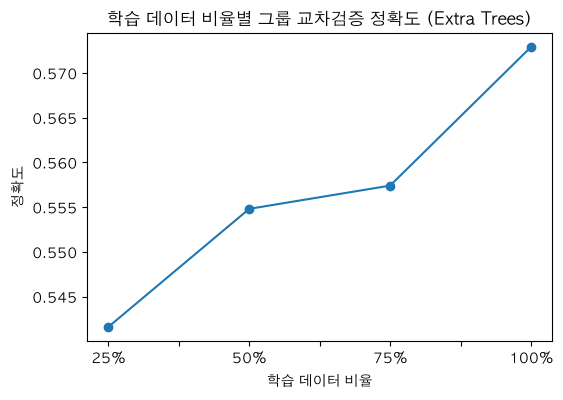

,정확도
25%,0.5416
50%,0.5548
75%,0.5574
100%,0.5729


In [37]:
curve = {}
for frac in [0.25, 0.5, 0.75, 1.0]:
    scores = []
    for train_idx, valid_idx in group_cv.split(X_common, y, groups):
        rng = np.random.RandomState(42)
        kept_groups = rng.choice(groups.iloc[train_idx].unique(), int(groups.iloc[train_idx].nunique() * frac), replace=False)
        sub_idx = train_idx[groups.iloc[train_idx].isin(kept_groups).values]
        scores.append((clone(et300).fit(X_common.iloc[sub_idx], y.iloc[sub_idx]).predict(X_common.iloc[valid_idx]) == y.iloc[valid_idx]).mean())
    curve[f'{frac:.0%}'] = round(np.mean(scores), 4)

pd.Series(curve).plot(marker='o', figsize=(6, 4), title='학습 데이터 비율별 그룹 교차검증 정확도 (Extra Trees)')
plt.xlabel('학습 데이터 비율')
plt.ylabel('정확도')
plt.show()
pd.Series(curve).to_frame('정확도')

### 5단계. 트리 모델끼리는 얼마나 비슷하게 틀리는가

In [38]:
pred = {name: classes[proba.argmax(axis=1)] for name, proba in oof_proba.items()}
pred['709'] = classes[(p['rf'] + p['et'] + p['stack']).argmax(axis=1)]
model_names = {'rf': '랜덤 포레스트', 'et': 'Extra Trees', 'cat': 'CatBoost', 'stack': '스태킹'}
pd.DataFrame({'단독 그룹 교차검증': [group_accuracy(oof_proba[a]) for a in model_names],
              '0.709 모델과 예측이 다른 비율': [round(np.mean(pred[a] != pred['709']), 3) for a in model_names]},
             index=model_names.values())

,단독 그룹 교차검증,0.709 모델과 예측이 다른 비율
랜덤 포레스트,0.5641,0.071
Extra Trees,0.5758,0.059
CatBoost,0.5658,0.128
스태킹,0.5863,0.065


**해석**

- 성분이 가장 가까운 다른 와인끼리도 품질이 같은 비율은 절반 안팎이다. ±1등급 이내로는 대부분 맞지만, 5·6·7 경계는 성분만으로 구별되지 않는 부분이 크다. 품질이 사람의 시음 평가이기 때문이다.
- 학습 데이터를 늘려도 정확도는 완만하게만 오른다. 모델을 바꿔서 얻을 수 있는 여지가 작다.
- 랜덤 포레스트·Extra Trees·스태킹은 0.709 모델과 예측이 다른 행이 6~7%뿐이다. 같은 행에서 함께 틀리므로, 이들을 다시 섞어도 새로운 정보가 거의 더해지지 않는다. CatBoost는 0.709 모델과 더 다르게 예측하지만 단독 정확도가 낮아, 다른 행을 맞히기보다 틀리는 경우가 많다.
- **결정**: 트리와 학습 원리가 다르면서도 단독 정확도가 0.709 수준인 모델을 찾아 결합한다.

---

# 14. 최종 모델

**질문**: 트리와 원리가 다른 모델을 더하면 같은 오답을 보완할 수 있는가.

**TabICL**은 대량의 합성 표 데이터로 미리 학습된 기초모델이다. 새 데이터에서 가중치를 다시 학습하지 않고, 학습 데이터 전체를 문맥으로 넣어 예측한다. 트리처럼 성분값을 기준선으로 나누지 않으므로, 트리 모델과 다른 행에서 다른 판단을 내릴 수 있다.

### 1단계. TabICL은 0.709 모델과 다르게 틀리는가

12장과 같은 그룹 교차검증 분할에서 TabICL의 확률을 만든다. 입력은 원래 성분 11개와 종류이고, 결과의 흔들림을 줄이기 위해 random_state 42, 7, 2026으로 학습한 확률을 평균한다.

In [39]:
X_tabicl = train[features].assign(is_white=(train['type'] == 'white').astype(int))
oof_tabicl = np.zeros((len(y), len(classes)))
for train_idx, valid_idx in group_cv.split(X_common, y, groups):
    oof_tabicl[valid_idx] = sum(TabICLClassifier(n_estimators=8, random_state=seed, device='cpu')
                                .fit(X_tabicl.iloc[train_idx], y.iloc[train_idx]).predict_proba(X_tabicl.iloc[valid_idx])
                                for seed in [42, 7, 2026]) / 3

proba_709_oof = (p['rf'] + p['et'] + p['stack']) / 3
pred_tabicl = classes[oof_tabicl.argmax(axis=1)]
pd.Series({'TabICL 단독 그룹 교차검증': group_accuracy(oof_tabicl),
           '0.709 모델 그룹 교차검증': group_accuracy(proba_709_oof),
           'TabICL과 0.709 모델의 예측이 다른 비율': round(np.mean(pred_tabicl != pred['709']), 3)}).to_frame('값')

,값
TabICL 단독 그룹 교차검증,0.584
0.709 모델 그룹 교차검증,0.582
TabICL과 0.709 모델의 예측이 다른 비율,0.105


### 2단계. 결합 비중

In [40]:
weight_table = {f'0.709 + {w} × TabICL': group_accuracy(proba_709_oof + w * oof_tabicl) for w in [0, 0.25, 0.5, 1.0]}
weight_df = pd.Series(weight_table).to_frame('그룹 교차검증')
weight_df['0.709 대비'] = weight_df['그룹 교차검증'] - weight_df.iloc[0, 0]
weight_df

,그룹 교차검증,0.709 대비
0.709 + 0 × TabICL,0.5820,0.0000
0.709 + 0.25 × TabICL,0.5856,0.0036
0.709 + 0.5 × TabICL,0.5880,0.0060
0.709 + 1.0 × TabICL,0.5878,0.0058


In [41]:
pred_blend = classes[(proba_709_oof + 0.5 * oof_tabicl).argmax(axis=1)]
changed = pred_blend != pred['709']
pd.Series({'결합으로 예측이 바뀐 행 수': int(changed.sum()),
           '그 행에서 결합 모델 정답률': round(np.mean(pred_blend[changed] == y[changed]), 3),
           '그 행에서 0.709 모델 정답률': round(np.mean(pred['709'][changed] == y[changed]), 3)}).to_frame('값')

,값
결합으로 예측이 바뀐 행 수,225.000
그 행에서 결합 모델 정답률,0.502
그 행에서 0.709 모델 정답률,0.356


- TabICL은 단독 정확도가 0.709 모델과 비슷하면서도(오히려 조금 높다), 0.709 모델과 예측이 다른 행이 랜덤 포레스트·Extra Trees·스태킹(6~7%)보다 많다. 정확도는 비슷한데 틀리는 행이 다르다는 뜻이다. 13장의 CatBoost처럼 다르게 예측하면서 정확도가 낮은 모델과 달리, 섞었을 때 서로의 오답을 보완할 수 있다.
- TabICL을 섞으면 0.709 모델이 확신하는 행은 그대로 두고, 두 모델의 확률 차이가 작은 경계 행에서만 예측이 바뀐다. 0.5 비중에서 바뀐 행을 보면 결합 모델이 0.709 모델보다 훨씬 더 많이 맞힌다.
- 이 분할에서는 0.5 비중이 가장 높고, 1.0으로 더 키우면 오히려 조금 내려간다. 분할을 3가지(random_state 42, 7, 2026)로 바꿔 확인해도 0.25와 0.5 비중이 모두 세 분할에서 0.709보다 높았다(0.25는 +0.0042, 0.5는 +0.0039~+0.0044).
- 두 비중의 교차검증 차이가 작아 리더보드로도 확인했다. 비중 0.25는 0.711, 0.35는 0.711, 0.5는 **0.712~0.713**(TabICL 확률이 실행 환경마다 미세하게 달라 경계의 한 행이 바뀜)으로, 교차검증과 같은 순서였다. 그래서 최종 비중은 0.5로 정했다.

### 3단계. 최종 학습과 제출 파일

전체 학습 데이터로 학습해 테스트를 예측한다.

- 최종 확률 = (랜덤 포레스트 + Extra Trees + 스태킹) / 3 + 0.5 × TabICL
- 테스트 중 학습 데이터와 성분이 같은 303행은 학습 데이터의 품질을 그대로 쓴다(2장).

In [42]:
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(X_common.drop(columns='bound_so2')), columns=X_common.columns.drop('bound_so2'))
X_test = pd.DataFrame(scaler.transform(X_test_common.drop(columns='bound_so2')), columns=X_common.columns.drop('bound_so2'))

inner_cv = StratifiedGroupKFold(3, shuffle=True, random_state=42)
stack_oof = [cross_val_predict(clone(m), X_common, y, cv=inner_cv, groups=groups, method='predict_proba') for m in [rf, et, cat]]
common_fitted = [clone(m).fit(X_common, y) for m in [rf, et, cat]]
meta = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=2000))
meta.fit(np.hstack(stack_oof), y)
stack_proba = meta.predict_proba(np.hstack([m.predict_proba(X_test_common) for m in common_fitted]))

fitted = [clone(m).fit(X, y) for m in [rf, et]]
proba_709 = (fitted[0].predict_proba(X_test) + fitted[1].predict_proba(X_test) + stack_proba) / 3

In [43]:
X_raw_test = test[features].assign(is_white=(test['type'] == 'white').astype(int))
tabicl_proba = sum(TabICLClassifier(n_estimators=8, random_state=seed, device='cpu').fit(X_raw, y).predict_proba(X_raw_test)
                   for seed in [42, 7, 2026]) / 3

final_proba = proba_709 + 0.5 * tabicl_proba
pred_final = fitted[0].classes_[final_proba.argmax(axis=1)]

known = make_x(train).assign(known_quality=train['quality']).drop_duplicates()
merged = make_x(test).merge(known, how='left')
pred_final = np.where(merged['known_quality'].notna(), merged['known_quality'], pred_final).astype(int)

submission = sub.copy()
submission['quality'] = pred_final
submission.to_csv('submission.csv', index=False)
pd.Series(pred_final).value_counts().sort_index().to_dict()

{4: 6, 5: 361, 6: 496, 7: 126, 8: 11}

**해석**

- 0.709 모델과 다른 행은 30행(6→5 12행, 6→7 8행, 7→6 5행, 5→6 4행, 4→5 1행)이고, 리더보드 **0.713**으로 0.709 모델보다 4행을 더 맞혔다.
- 0.709 이후 처음으로 그룹 교차검증과 리더보드가 같은 방향을 가리켰다.

---

# 종합

## 1. 데이터의 구조가 검증 방식을 정했다

학습 데이터의 15.6%가 중복 행이고 테스트의 30.3%가 학습 데이터와 같다. 일반 교차검증은 이미 본 와인을 다시 맞힌 몫 때문에 약 0.10 부풀려졌다. 그래서 중복을 고려한 그룹 교차검증으로 모델을 확인했고, 303행은 학습 데이터의 품질을 그대로 썼다.

## 2. 성분과 품질의 관계가 모델을 정했다

품질과 가장 관련이 큰 도수도 상관계수가 0.44에 그쳤고, 고등급과 저등급을 가르는 변수가 달랐으며, 레드와 화이트에서 상관 방향이 반대인 변수도 있었다. 여러 성분과 종류의 조합을 스스로 학습하는 트리 앙상블이 맞았고, 랜덤 포레스트 + Extra Trees + 스태킹이 리더보드 0.709를 기록했다.

## 3. 효과가 없던 실험도 결정의 근거였다

| 실험 | 결과 | 결정 |
|---|---|---|
| 중복 제거 | 크게 하락 | 중복 유지 |
| 불균형 처리 6가지 | 의미 있게 오른 방법 없음, 폴드 밖 리샘플링은 점수 부풀림 | 처리 안 함 |
| 상관이 약한 변수 제거 | 하락 | 모든 변수 유지 |
| 레드·화이트 분리 | 표준편차 안의 차이 | 통합 모델 |
| 0.709 변형 약 100가지 | 리더보드 15개 모두 0.697~0.708 | 원인 분석 |

## 4. 같은 오답을 내는 모델끼리는 서로를 보완하지 못한다

0.709 이후의 정체는 모델이 부족해서가 아니었다. 성분이 가장 가까운 와인끼리도 품질이 같은 비율이 절반 안팎일 만큼 라벨 자체의 변동이 컸고, 트리 모델들은 같은 행에서 함께 틀렸다. 그래서 트리와 원리가 다른 TabICL을 더해 서로 다른 오답을 보완했고, 리더보드 **0.713**을 얻었다.

## 한계

- 0.709와 0.713의 차이는 1,000행 중 4행으로, 리더보드의 표준오차(약 14.5행)보다 작다. 다만 그룹 교차검증에서도 분할 3가지 모두 같은 방향으로 올랐다.
- 3·4·8·9등급은 여전히 거의 맞히지 못한다. 성분만으로는 극단 등급을 구별할 정보가 부족하다.
- 트리 모델의 학습 계산은 CPU 종류에 따라 미세하게 달라진다. 이 노트북은 Apple 칩 맥북(Python 3.14, `requirements.txt`의 버전)에서 실행했으며, Intel 계열 CPU(예: Google Colab)에서는 경계의 몇 행이 바뀔 수 있다.